# RGB Image Quality Analysis under Adverse Environmental Conditions

**Author:** Maritza Alban  
**Dataset:** *Seeing Through Fog*  
**Field:** Autonomous Systems — Perception  
**Stage:** Stage 1 — RGB Camera Baseline  
**Format:** Reproducible technical report

---

## Executive Summary

This report characterizes the visual quality of **12,997 RGB images** from the *Seeing Through Fog* dataset. Three image-level indicators are analyzed: mean brightness, global contrast, and Laplacian variance as a proxy for sharpness. These indicators are examined against the available environmental annotations: fog, precipitation, illumination, and road condition.

The descriptive results show a progressive decrease in median sharpness from no-fog images to light-fog and dense-fog images. Median contrast also decreases across precipitation categories, from no precipitation to heavy snow. Among the observed environmental combinations, **dense fog + heavy snow** has the lowest median contrast and sharpness.

These findings describe image characteristics; they do not yet demonstrate an equivalent reduction in object-detector performance. That relationship must be evaluated in the next stage using verified 2D annotations and detection metrics such as Precision, Recall, and mAP.

## 1. Background and Motivation

In autonomous driving systems, cameras provide rich semantic information, but their signals can be affected by weather and illumination conditions. Fog, rain, snow, darkness, and exposure changes can alter scene appearance and make visual feature extraction more difficult.

Before evaluating an object detector, it is useful to characterize the RGB signal and understand how its properties vary under the annotated environmental conditions. This analysis establishes an image-quality baseline to guide subsequent work on robust perception and multi-sensor fusion.

The analysis uses images from the left stereo camera in 8-bit LUT format (`cam_stereo_left_lut`) and the corresponding refined environmental annotations.

## 2. Objectives and Scope

### Overall Objective

Characterize variations in brightness, contrast, and sharpness in RGB images from the *Seeing Through Fog* dataset according to the available environmental annotations.

### Specific Objectives

1. Integrate existing RGB image metrics with environmental annotations using the image identifier.
2. Describe the distributions of fog, precipitation, illumination, and road condition.
3. Analyze brightness against illumination, sharpness against fog, and contrast against precipitation.
4. Examine the joint distribution of fog and precipitation.
5. Quantify descriptive differences relative to a reference condition.
6. Identify methodological limitations and define the next step toward 2D object-detection evaluation.

### Out of Scope

- No YOLO detector is trained or validated in this report.
- Precision, Recall, F1-score, and mAP are not calculated.
- No causal relationship between environmental labels and image metrics is claimed.
- LiDAR, radar, and multimodal fusion performance are not evaluated at this stage.

## 3. Dataset and Input Data

The analysis uses a previously prepared master CSV file containing one row per image. This file combines RGB image metrics with normalized environmental labels.

**Input file:** `rgb_image_quality_with_environmental_labels.csv`

Main columns:

| Field | Description |
|---|---|
| `image_name` | RGB image identifier |
| `brightness_mean` | Mean grayscale intensity |
| `contrast_std` | Standard deviation of grayscale intensity |
| `sharpness_laplacian_var` | Laplacian variance |
| `fog_condition` | `none`, `light`, `dense` |
| `precipitation_condition` | `none`, `rain`, `light_snow`, `heavy_snow` |
| `daytime_condition` | `day`, `night` |
| `twilight` | Independent Boolean label |
| `road_condition` | `dry`, `wet`, `partial_snow`, `full_snow`, `unknown` |

### Master CSV Usage

Image metrics have already been calculated for all 12,997 images. Therefore, this report loads the integrated CSV instead of decoding the images again or rebuilding labels from the ZIP archive. This avoids redundant processing and makes the statistical and graphical analysis reproducible.

## 4. Data Configuration and Loading

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import kruskal, rankdata, norm, pearsonr, spearmanr
from itertools import combinations

# Ruta del proyecto en el entorno WSL.
PROJECT_ROOT = Path("/home/maritza/projects/autonomous_vehicle")
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "stage1_rgb_baseline"

MASTER_CSV_PATH = (
    OUTPUT_DIR / "rgb_image_quality_with_environmental_labels.csv"
)

FIGURES_DIR = OUTPUT_DIR / "report_figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

if not MASTER_CSV_PATH.exists():
    raise FileNotFoundError(
        f"No se encontró el CSV maestro: {MASTER_CSV_PATH}"
    )

df = pd.read_csv(MASTER_CSV_PATH)
df["twilight"] = df["twilight"].astype("boolean")

required_columns = [
    "image_name",
    "brightness_mean",
    "contrast_std",
    "sharpness_laplacian_var",
    "fog_condition",
    "precipitation_condition",
    "daytime_condition",
    "twilight",
    "road_condition"
]

missing_columns = [c for c in required_columns if c not in df.columns]
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

print(f"Registros: {len(df):,}")
print(f"Imágenes únicas: {df['image_name'].nunique():,}")
print(f"Columnas disponibles: {len(df.columns)}")
display(df[required_columns].head())

Registros: 12,997
Imágenes únicas: 12,997
Columnas disponibles: 16


,image_name,brightness_mean,contrast_std,sharpness_laplacian_var,fog_condition,precipitation_condition,daytime_condition,twilight,road_condition
0,2018-02-03_20-48-35_00400.png,59.669750,31.763117,188.831076,none,rain,night,False,dry
1,2018-02-03_20-48-35_00500.png,71.708850,40.803782,209.826554,none,rain,night,False,dry
2,2018-02-03_20-49-38_00000.png,73.818069,42.530226,220.990323,none,rain,night,False,dry
3,2018-02-03_20-49-38_00100.png,90.246356,48.473986,198.211996,none,rain,night,False,dry
4,2018-02-03_20-49-38_00200.png,70.095635,39.496374,223.368093,none,rain,night,False,dry


### 4.1 Dataset Validation

The following checks confirm that the CSV contains the required columns, that image identifiers are unique, and that the essential metrics do not contain missing values. This validation helps prevent analysis from silently proceeding with an incomplete table.

In [2]:
print("DATASET VALIDATION")
print("=" * 60)
print("Duplicados de image_name:", df["image_name"].duplicated().sum())

quality_columns = [
    "brightness_mean",
    "contrast_std",
    "sharpness_laplacian_var"
]

print("\nMissing values in image metrics:")
display(df[quality_columns].isna().sum())

print("\nMissing values in environmental labels:")
display(df[
    ["fog_condition", "precipitation_condition",
     "daytime_condition", "twilight", "road_condition"]
].isna().sum())

assert df["image_name"].is_unique, "Hay identificadores de imagen duplicados."
assert len(df) == 12997, "El número de registros no coincide con el conjunto analizado."

DATASET VALIDATION
Duplicados de image_name: 0

Missing values in image metrics:


brightness_mean            0
contrast_std               0
sharpness_laplacian_var    0
dtype: int64


Missing values in environmental labels:


fog_condition              0
precipitation_condition    0
daytime_condition          0
twilight                   0
road_condition             0
dtype: int64

## 5. Image Metrics: Definitions and Interpretation

### 5.1 Mean Brightness

Mean pixel intensity after conversion to grayscale. For `uint8` images, values range from 0 to 255. It describes overall luminance but does not, by itself, measure object visibility.

### 5.2 Global Contrast

Calculated as the standard deviation of grayscale intensities. A lower value indicates that pixel intensities are more concentrated around the mean. This is a global indicator: it does not describe the local contrast of individual objects or regions of interest.

### 5.3 Laplacian-Variance Sharpness

The Laplacian responds to spatial intensity changes. Its variance is used as an indicator of high-frequency content and edge definition. Lower values are often associated with smoother or less sharply defined images, but the metric is also affected by texture, noise, motion, and scene content.

**Important:** none of these three metrics is directly equivalent to human visibility or object-detection accuracy.

## 6. Distribution of Environmental Conditions

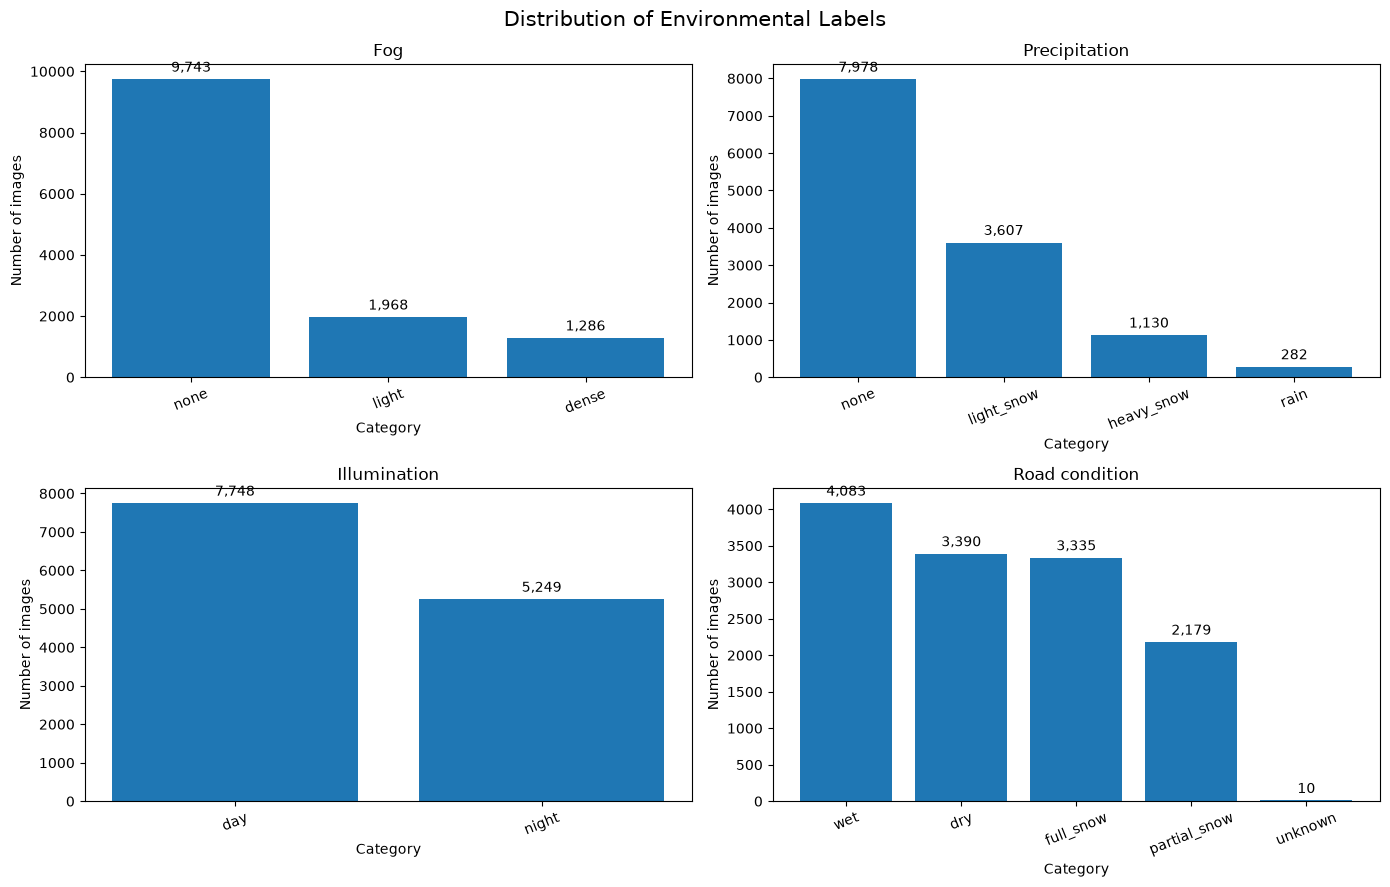

Twilight distribution:


twilight
False    10869
True      2128
Name: count, dtype: Int64

In [3]:
environmental_fields = {
    "Fog": "fog_condition",
    "Precipitation": "precipitation_condition",
    "Illumination": "daytime_condition",
    "Road condition": "road_condition"
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.ravel()

for ax, (title, column) in zip(axes, environmental_fields.items()):
    counts = df[column].value_counts()
    bars = ax.bar(counts.index.astype(str), counts.values)
    ax.set_title(title)
    ax.set_xlabel("Category")
    ax.set_ylabel("Number of images")
    ax.tick_params(axis="x", rotation=22)
    ax.bar_label(bars, labels=[f"{v:,}" for v in counts.values], padding=3)

plt.suptitle("Distribution of Environmental Labels", fontsize=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_environmental_distributions.png", dpi=180)
plt.show()

print("Twilight distribution:")
display(df["twilight"].value_counts(dropna=False))

### 6.1 Results and Interpretation

The observed distribution is:

- **Fog:** 9,743 images with no fog, 1,968 with light fog, and 1,286 with dense fog.
- **Precipitation:** 7,978 with no precipitation, 3,607 with light snow, 1,130 with heavy snow, and 282 with rain.
- **Illumination:** 7,748 images labelled as day and 5,249 as night.
- **Twilight:** 2,128 images carry this label, while 10,869 do not.

The distribution is imbalanced. In particular, rain and some fog/precipitation combinations have substantially fewer samples than the most frequent conditions. This imbalance must be considered when interpreting comparisons.

## 7. Relationship between Brightness and Illumination

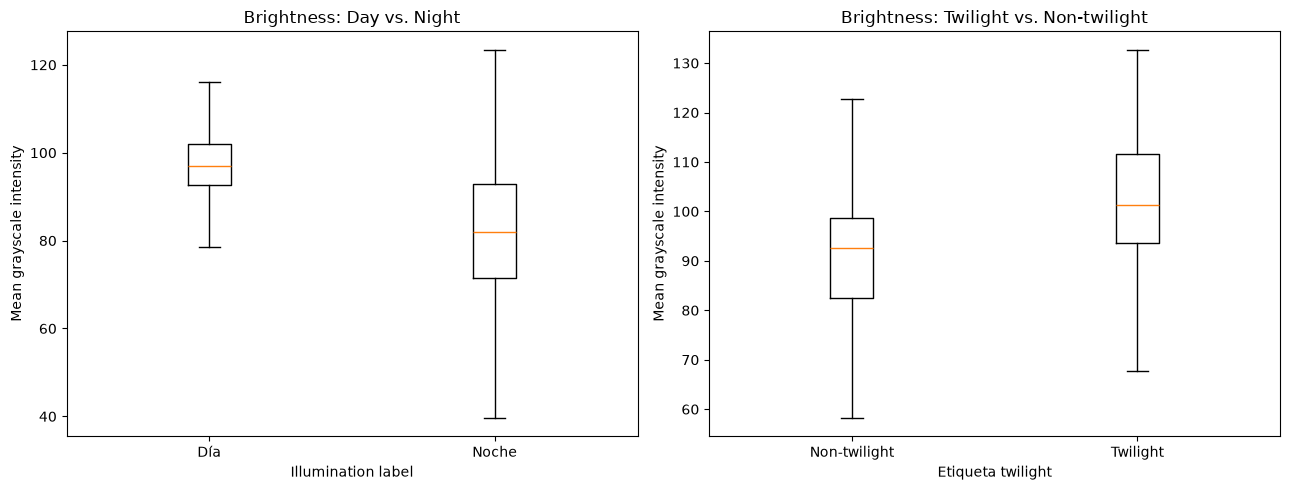

,count,mean,median,std
daytime_condition,,,,
day,7748,99.32,96.90,10.40
night,5249,81.34,82.06,17.28


,count,mean,median,std
twilight,,,,
False,10869,90.10,92.70,16.34
True,2128,102.09,101.26,11.03


In [4]:
# Brightness boxplots for day/night and twilight/non-twilight.
day_groups = [
    df.loc[df["daytime_condition"] == label, "brightness_mean"].dropna()
    for label in ["day", "night"]
]
twilight_groups = [
    df.loc[df["twilight"] == label, "brightness_mean"].dropna()
    for label in [False, True]
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].boxplot(day_groups, tick_labels=["Día", "Noche"], showfliers=False)
axes[0].set_title("Brightness: Day vs. Night")
axes[0].set_ylabel("Mean grayscale intensity")
axes[0].set_xlabel("Illumination label")

axes[1].boxplot(
    twilight_groups,
    tick_labels=["Non-twilight", "Twilight"],
    showfliers=False
)
axes[1].set_title("Brightness: Twilight vs. Non-twilight")
axes[1].set_ylabel("Mean grayscale intensity")
axes[1].set_xlabel("Etiqueta twilight")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_brightness_illumination.png", dpi=180)
plt.show()

brightness_day_night = (
    df.groupby("daytime_condition")["brightness_mean"]
    .agg(["count", "mean", "median", "std"]).round(2)
)
brightness_twilight = (
    df.groupby("twilight", dropna=False)["brightness_mean"]
    .agg(["count", "mean", "median", "std"]).round(2)
)

display(brightness_day_night)
display(brightness_twilight)

### 7.1 Results and Interpretation

Mean brightness is 99.32 during the day and 81.34 at night. The medians are 96.90 and 82.06, respectively. Brightness is also more dispersed at night (standard deviation 17.28 versus 10.40).

The median brightness for the twilight group is 101.26, compared with 92.70 for the non-twilight group. However, `twilight` is not an exclusive third category: it can coexist with either `day` or `night`. Therefore, the aggregate twilight/non-twilight comparison combines different illumination situations.

### 7.2 Joint Breakdown of Day/Night and Twilight

twilight,False,True,All
daytime_condition,,,
day,6412,1336,7748
night,4457,792,5249
All,10869,2128,12997


count    mean  median    std
daytime_condition twilight                              
day               False      6412   98.69   96.82  10.07
                  True       1336  102.33   97.70  11.38
night             False      4457   77.73   79.36  15.69
                  True        792  101.67  103.12  10.41

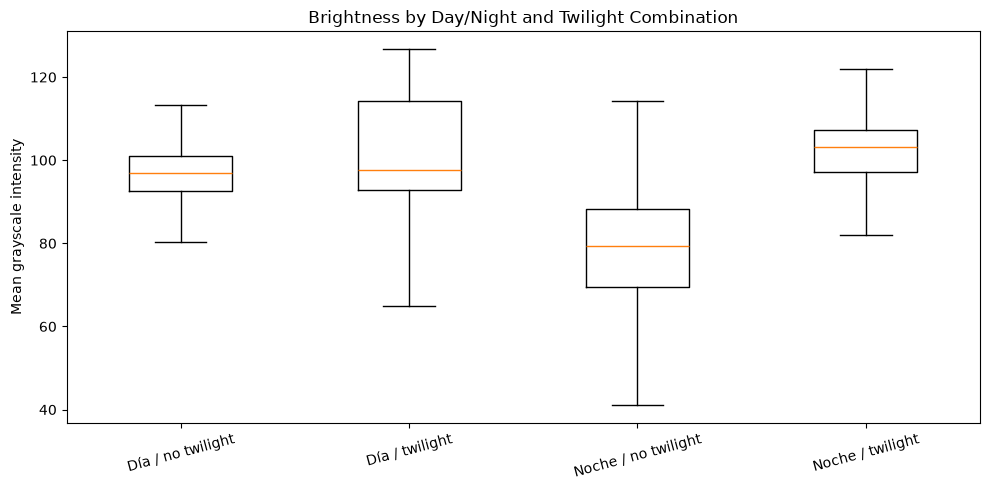

In [5]:
illumination_counts = pd.crosstab(
    df["daytime_condition"], df["twilight"], margins=True
)

illumination_stats = (
    df.groupby(["daytime_condition", "twilight"])["brightness_mean"]
    .agg(["count", "mean", "median", "std"]).round(2)
)

display(illumination_counts)
display(illumination_stats)

combo_order = [("day", False), ("day", True), ("night", False), ("night", True)]
combo_groups = [
    df.loc[
        (df["daytime_condition"] == day_label) &
        (df["twilight"] == twilight_label),
        "brightness_mean"
    ].dropna()
    for day_label, twilight_label in combo_order
]

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    combo_groups,
    tick_labels=["Día / no twilight", "Día / twilight",
                 "Noche / no twilight", "Noche / twilight"],
    showfliers=False
)
ax.set_title("Brightness by Day/Night and Twilight Combination")
ax.set_ylabel("Mean grayscale intensity")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_brightness_day_twilight.png", dpi=180)
plt.show()

### 7.3 Interpretation

The largest difference occurs within the group labelled as night: the median is 79.36 for night/non-twilight and 103.12 for night/twilight. Within the day group, the medians are closer: 96.82 and 97.70.

This breakdown explains why the aggregate twilight group had a higher median brightness. It should not be interpreted as evidence that twilight is generally brighter than daytime; it reflects the composition of the labels in this dataset.

## 8. Relationship between Sharpness and Fog

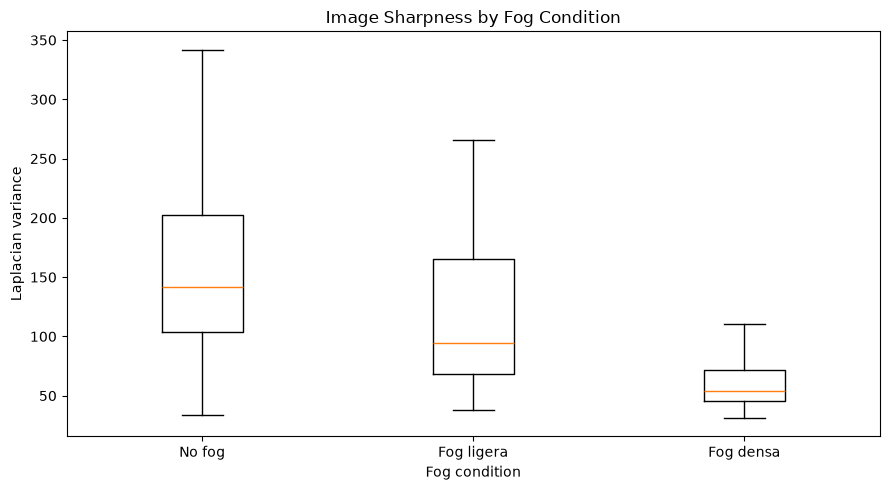

,count,mean,median,std
fog_condition,,,,
none,9743,151.61,141.37,56.29
light,1968,115.17,94.76,54.99
dense,1286,75.28,54.13,50.63


In [6]:
fog_order = ["none", "light", "dense"]
fog_sharpness_groups = [
    df.loc[
        df["fog_condition"] == category,
        "sharpness_laplacian_var"
    ].dropna()
    for category in fog_order
]

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(
    fog_sharpness_groups,
    tick_labels=["No fog", "Fog ligera", "Fog densa"],
    showfliers=False
)
ax.set_title("Image Sharpness by Fog Condition")
ax.set_xlabel("Fog condition")
ax.set_ylabel("Laplacian variance")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_sharpness_fog.png", dpi=180)
plt.show()

sharpness_fog_stats = (
    df.groupby("fog_condition")["sharpness_laplacian_var"]
    .agg(["count", "mean", "median", "std"])
    .reindex(fog_order).round(2)
)
display(sharpness_fog_stats)

### 8.1 Results and Interpretation

Median sharpness decreases from 141.37 (no fog) to 94.76 (light fog) and 54.13 (dense fog). This progression is consistent with a reduction in high-frequency edge content in images labelled with fog.

This is a descriptive finding. Laplacian variance is also affected by scene content, texture, and noise, so the difference cannot be attributed exclusively to fog.

### 8.2 Statistical Comparison of Fog Groups: Kruskal–Wallis and Dunn–Holm

In [7]:
# Kruskal–Wallis: a non-parametric omnibus test for comparing distributions.

### 8.3 Statistical Interpretation

The previous analysis yielded H = 2432.30 for the Kruskal–Wallis test. All three pairwise comparisons (no fog/light fog, no fog/dense fog, and light fog/dense fog) were significant after Holm correction.

The omnibus result indicates that at least one distribution differs; the post-hoc comparisons identify the pairs showing differences. Very small p-values do not quantify practical effect size. In addition, images from the same temporal sequence may be correlated, whereas these tests treat rows as independent observations.

## 9. Relationship between Contrast and Precipitation

In [12]:
# 9.2.1 — Statistical Test Function: Dunn with Holm Correction

from scipy.stats import rankdata, norm
from itertools import combinations

def dunn_holm(data, group_col, value_col, categories):

    work = data[[group_col, value_col]].dropna().copy()
    work["rank"] = rankdata(work[value_col])

    group_stats = work.groupby(group_col).agg(
        n=("rank", "count"),
        mean_rank=("rank", "mean")
    )

    n_total = len(work)

    # Tie correction
    ties = work[value_col].value_counts()
    tie_sum = sum(t**3 - t for t in ties)
    tie_correction = 1 - tie_sum / (n_total**3 - n_total)

    pooled_variance = (
        n_total * (n_total + 1) / 12
    ) * tie_correction

    results = []

    # Pairwise Dunn comparisons
    for group_a, group_b in combinations(categories, 2):

        n_a = group_stats.loc[group_a, "n"]
        n_b = group_stats.loc[group_b, "n"]

        mean_a = group_stats.loc[group_a, "mean_rank"]
        mean_b = group_stats.loc[group_b, "mean_rank"]

        standard_error = np.sqrt(
            pooled_variance * (1 / n_a + 1 / n_b)
        )

        z_score = (mean_a - mean_b) / standard_error
        p_value = 2 * norm.sf(abs(z_score))

        results.append({
            "comparison": f"{group_a} vs {group_b}",
            "z_score": z_score,
            "p_raw": p_value
        })

    result = pd.DataFrame(results)

    # Holm multiple-comparison correction
    sorted_indices = np.argsort(result["p_raw"].values)

    adjusted_p = np.empty(len(result))
    running_max = 0
    m = len(result)

    for rank, index in enumerate(sorted_indices):
        corrected_p = (m - rank) * result.loc[index, "p_raw"]
        running_max = max(running_max, corrected_p)
        adjusted_p[index] = min(running_max, 1.0)

    result["p_holm"] = adjusted_p
    result["significant"] = result["p_holm"] < 0.05

    return result

### 9.1 Results and Interpretation

Median contrast decreases from 40.53 with no precipitation to 38.97 with rain, 37.29 with light snow, and 34.14 with heavy snow. Heavy snow has the lowest median among the observed precipitation categories.

The rain category contains 282 images, substantially fewer than the no-precipitation and light-snow categories. The rain comparison should therefore be interpreted with this sample-size imbalance in mind.

### 9.2 Statistical Comparison of Precipitation Categories: Kruskal–Wallis and Dunn–Holm

In [13]:
kw_precip = kruskal(*contrast_groups)
print(f"H = {kw_precip.statistic:.4f}")
print(f"p = {kw_precip.pvalue:.6e}")

dunn_precip = dunn_holm(df, "precipitation_condition", "contrast_std", precip_order)
display(dunn_precip)

H = 1337.7500
p = 9.478488e-290


,comparison,z_score,p_raw,p_holm,significant
0,none vs rain,3.788438,1.515974e-04,2.360217e-04,True
1,none vs light_snow,23.305963,3.857163e-120,1.928581e-119,True
2,none vs heavy_snow,32.218944,9.582385e-228,5.749431e-227,True
3,rain vs light_snow,3.850222,1.180108e-04,2.360217e-04,True
4,rain vs heavy_snow,11.936027,7.680475e-33,2.304142e-32,True
5,light_snow vs heavy_snow,16.322922,6.781081e-60,2.712432e-59,True


### 9.3 Statistical Interpretation

The previous analysis yielded H = 1337.75 and p = 9.48 × 10⁻²⁹⁰ for the Kruskal–Wallis test. All six pairwise comparisons were significant after Holm correction.

This indicates differences between the contrast distributions of the observed categories. It does not prove that precipitation is the only cause: illumination, scene content, road condition, exposure, and other factors may also contribute.

## 10. Association between Brightness and Sharpness by Illumination

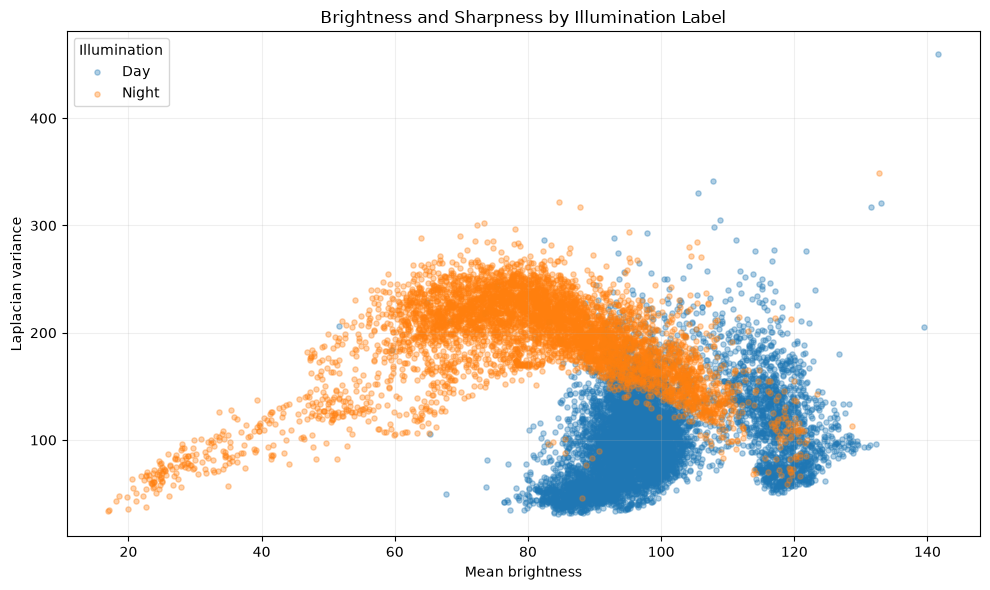

,illumination,count,pearson_r,pearson_p,spearman_rho,spearman_p
0,day,7748,0.303819,0.000000,0.372520,0.0
1,night,5249,-0.001461,0.915714,-0.279007,0.0


In [14]:
fig, ax = plt.subplots(figsize=(10, 6))

for label in ["day", "night"]:
    subset = df[df["daytime_condition"] == label]
    ax.scatter(
        subset["brightness_mean"],
        subset["sharpness_laplacian_var"],
        label=label.capitalize(),
        alpha=0.35,
        s=14
    )

ax.set_title("Brightness and Sharpness by Illumination Label")
ax.set_xlabel("Mean brightness")
ax.set_ylabel("Laplacian variance")
ax.legend(title="Illumination")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "06_brightness_sharpness.png", dpi=180)
plt.show()

correlation_rows = []
for label in ["day", "night"]:
    subset = df.loc[
        df["daytime_condition"] == label,
        ["brightness_mean", "sharpness_laplacian_var"]
    ].dropna()

    pr, pp = pearsonr(subset["brightness_mean"], subset["sharpness_laplacian_var"])
    sr, sp = spearmanr(subset["brightness_mean"], subset["sharpness_laplacian_var"])

    correlation_rows.append({
        "illumination": label,
        "count": len(subset),
        "pearson_r": pr,
        "pearson_p": pp,
        "spearman_rho": sr,
        "spearman_p": sp
    })

correlations = pd.DataFrame(correlation_rows)
display(correlations.round(6))

### 10.1 Results and Interpretation

For the day group, Pearson r = 0.304 and Spearman ρ = 0.373; both indicate a moderate positive association. For the night group, Pearson r = −0.001 (p = 0.916), while Spearman ρ = −0.279 (p < 0.001).

The difference between Pearson and Spearman at night suggests that the relationship is not well described by a simple linear association and may contain a negative monotonic trend. A significant correlation in one group and a non-significant correlation in another does not, by itself, demonstrate that the two group correlations are significantly different.

## 11. Joint Distribution of Fog and Precipitation

precipitation_condition,none,rain,light_snow,heavy_snow
fog_condition,,,,
none,6618,282,2658,185
light,263,0,904,801
dense,1097,0,45,144


precipitation_condition,none,rain,light_snow,heavy_snow
fog_condition,,,,
none,50.92,2.17,20.45,1.42
light,2.02,0.00,6.96,6.16
dense,8.44,0.00,0.35,1.11


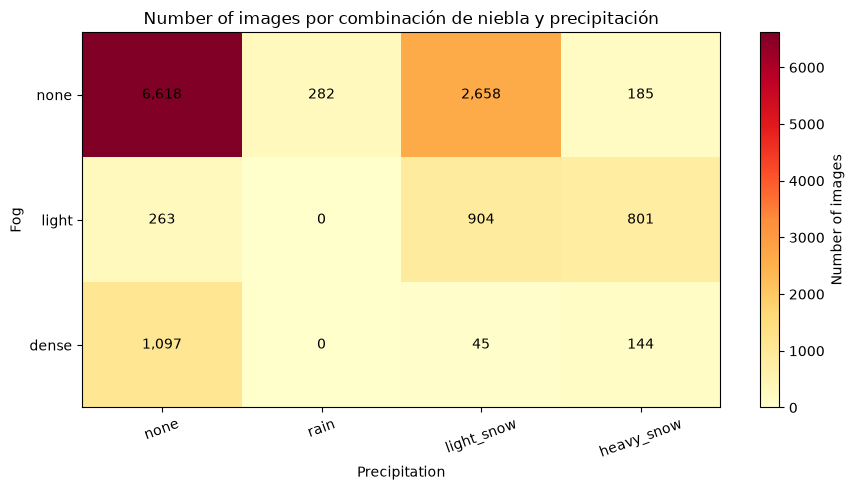

In [15]:
fog_order = ["none", "light", "dense"]
precip_order = ["none", "rain", "light_snow", "heavy_snow"]

fog_precip_counts = pd.crosstab(
    df["fog_condition"], df["precipitation_condition"]
).reindex(index=fog_order, columns=precip_order, fill_value=0)

fog_precip_percent = (fog_precip_counts / len(df) * 100).round(2)

display(fog_precip_counts)
display(fog_precip_percent)

fig, ax = plt.subplots(figsize=(9, 5))
im = ax.imshow(fog_precip_counts.values, cmap="YlOrRd", aspect="auto")
ax.set_xticks(range(len(precip_order)))
ax.set_xticklabels(precip_order, rotation=20)
ax.set_yticks(range(len(fog_order)))
ax.set_yticklabels(fog_order)
ax.set_xlabel("Precipitation")
ax.set_ylabel("Fog")
ax.set_title("Number of images por combinación de niebla y precipitación")

for i in range(len(fog_order)):
    for j in range(len(precip_order)):
        ax.text(j, i, f"{fog_precip_counts.iloc[i, j]:,}",
                ha="center", va="center", color="black")

fig.colorbar(im, ax=ax, label="Number of images")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_fog_precipitation_counts.png", dpi=180)
plt.show()

### 11.1 Results and Interpretation: Imbalanced Coverage

The contingency table shows that rain appears exclusively in the `fog_condition = none` row:

| Fog condition | No precipitation | Rain | Light snow | Heavy snow |
|---|---:|---:|---:|---:|
| No fog | 6,618 | 282 | 2,658 | 185 |
| Light fog | 263 | **0** | 904 | 801 |
| Dense fog | 1,097 | **0** | 45 | 144 |

**Why does rain not overlap with fog in this table?** Because, among the 12,997 annotations used here, no image is simultaneously labelled `rain = True` and either `light_fog = True` or `dense_fog = True`. All 282 rain-labelled images are classified as `fog_condition = none`.

This describes the composition of the annotations and the selected subset. **It does not mean that rain and fog cannot coexist in the real world.** It may reflect the conditions captured during dataset acquisition, scenario sampling, or annotation decisions. This subset cannot be used to study the combined effect of rain and fog.

The most represented combinations are no fog/no precipitation (6,618), no fog/light snow (2,658), light fog/light snow (904), light fog/heavy snow (801), and dense fog/no precipitation (1,097). Dense fog/light snow contains only 45 images; its statistics are particularly uncertain.

## 12. Image Quality by Environmental Combination

In [16]:
quality_by_environment = (
    df.groupby(["fog_condition", "precipitation_condition"], observed=True)
    .agg(
        image_count=("image_name", "count"),
        brightness_median=("brightness_mean", "median"),
        contrast_median=("contrast_std", "median"),
        sharpness_median=("sharpness_laplacian_var", "median")
    )
    .reset_index()
)

quality_by_environment = quality_by_environment.sort_values(
    ["fog_condition", "precipitation_condition"]
)

display(quality_by_environment.round(2))

,fog_condition,precipitation_condition,image_count,brightness_median,contrast_median,sharpness_median
0,dense,heavy_snow,144,94.92,29.05,50.84
1,dense,light_snow,45,109.00,30.60,59.76
2,dense,none,1097,87.64,31.84,54.51
3,light,heavy_snow,801,97.21,34.14,75.88
4,light,light_snow,904,96.41,35.64,147.13
5,light,none,263,90.12,35.90,86.50
6,none,heavy_snow,185,98.78,37.20,86.59
7,none,light_snow,2658,95.82,38.21,137.55
8,none,none,6618,93.61,41.79,143.69
9,none,rain,282,83.64,38.97,198.82


### 12.1 Interpretation

The `dense fog + heavy snow` combination has the lowest median contrast (29.05) and sharpness (50.84) among the observed combinations. `Dense fog + no precipitation` also has low values: contrast 31.84 and sharpness 54.51.

There are relevant exceptions. `No fog + rain` has a median sharpness of 198.82, higher than the reference condition without fog or precipitation (143.69). `Light fog + light snow` has a median of 147.13. These values do not demonstrate that rain or light snow improve image quality: they may reflect differences in scene content, texture, motion, illumination, and sample size.

### 12.2 Heatmaps of Median Values

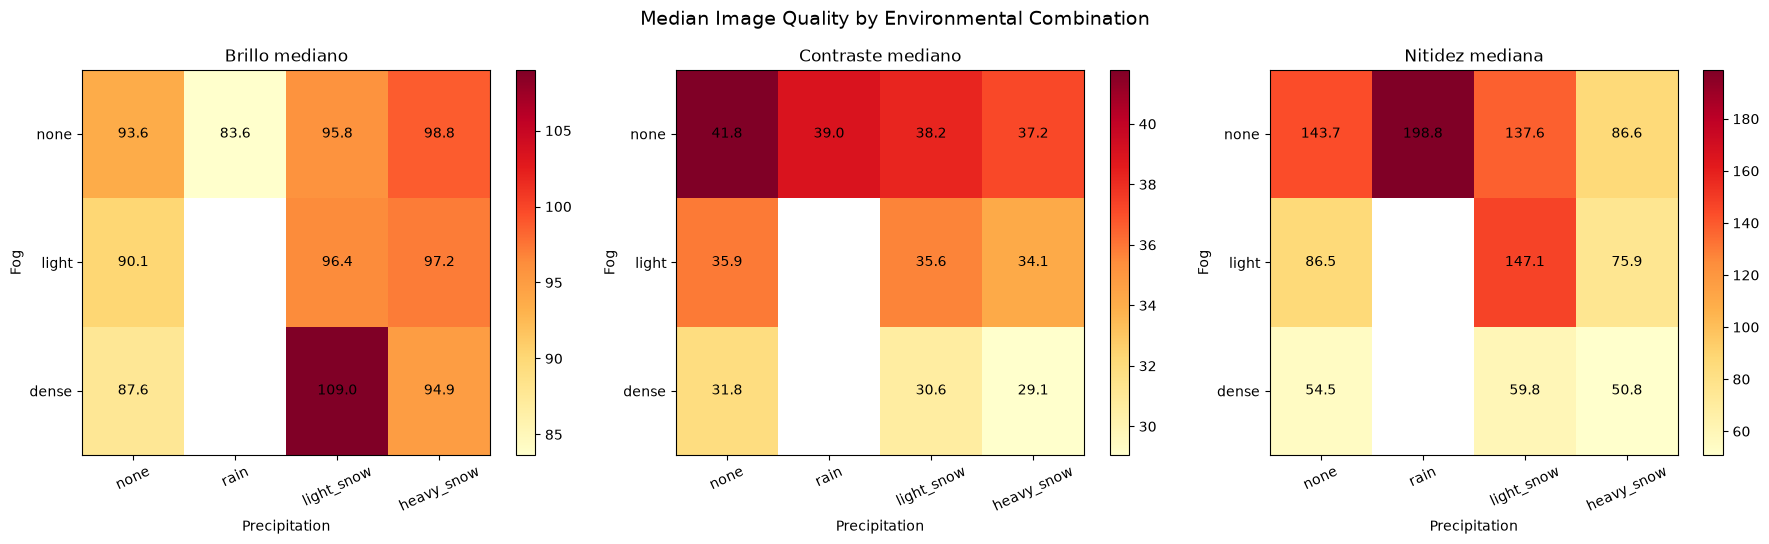

In [17]:
metric_titles = {
    "brightness_median": "Brillo mediano",
    "contrast_median": "Contraste mediano",
    "sharpness_median": "Nitidez mediana"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (metric, title) in zip(axes, metric_titles.items()):
    matrix = quality_by_environment.pivot(
        index="fog_condition",
        columns="precipitation_condition",
        values=metric
    ).reindex(index=fog_order, columns=precip_order)

    values = matrix.to_numpy(dtype=float)
    im = ax.imshow(values, cmap="YlOrRd", aspect="auto")

    ax.set_xticks(range(len(precip_order)))
    ax.set_xticklabels(precip_order, rotation=25)
    ax.set_yticks(range(len(fog_order)))
    ax.set_yticklabels(fog_order)
    ax.set_title(title)
    ax.set_xlabel("Precipitation")
    ax.set_ylabel("Fog")

    for i in range(len(fog_order)):
        for j in range(len(precip_order)):
            value = values[i, j]
            if np.isfinite(value):
                ax.text(j, i, f"{value:.1f}", ha="center", va="center")

    fig.colorbar(im, ax=ax)

plt.suptitle("Median Image Quality by Environmental Combination", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "08_environmental_quality_heatmaps.png", dpi=180)
plt.show()

### 12.3 Reading the Heatmaps

Each panel has its own colour scale. Comparisons should therefore be made using the numerical values for each metric, not by comparing colour intensity across panels. White cells indicate combinations with no samples.

Brightness does not follow a uniform trend. By contrast, contrast and sharpness are particularly low in the dense-fog groups. The dense fog + heavy snow result is consistent with the marginal analyses, although this group contains 144 images.

## 13. Relative Variation from the Reference Condition

In [18]:
reference = quality_by_environment.loc[
    (quality_by_environment["fog_condition"] == "none") &
    (quality_by_environment["precipitation_condition"] == "none")
].iloc[0]

relative_quality = quality_by_environment.copy()

reference_metrics = {
    "brightness_median": reference["brightness_median"],
    "contrast_median": reference["contrast_median"],
    "sharpness_median": reference["sharpness_median"]
}

for metric, ref_value in reference_metrics.items():
    output_col = metric.replace("_median", "_variation_pct")
    relative_quality[output_col] = (
        (relative_quality[metric] - ref_value) / ref_value
    ) * 100

variation_columns = [
    "brightness_variation_pct",
    "contrast_variation_pct",
    "sharpness_variation_pct"
]

display(relative_quality[
    ["fog_condition", "precipitation_condition", "image_count", *variation_columns]
].round(2))

,fog_condition,precipitation_condition,image_count,brightness_variation_pct,contrast_variation_pct,sharpness_variation_pct
0,dense,heavy_snow,144,1.40,-30.48,-64.62
1,dense,light_snow,45,16.44,-26.78,-58.41
2,dense,none,1097,-6.38,-23.80,-62.06
3,light,heavy_snow,801,3.84,-18.30,-47.19
4,light,light_snow,904,2.99,-14.71,2.40
5,light,none,263,-3.73,-14.10,-39.80
6,none,heavy_snow,185,5.52,-10.97,-39.74
7,none,light_snow,2658,2.35,-8.57,-4.27
8,none,none,6618,0.00,0.00,0.00
9,none,rain,282,-10.65,-6.74,38.37


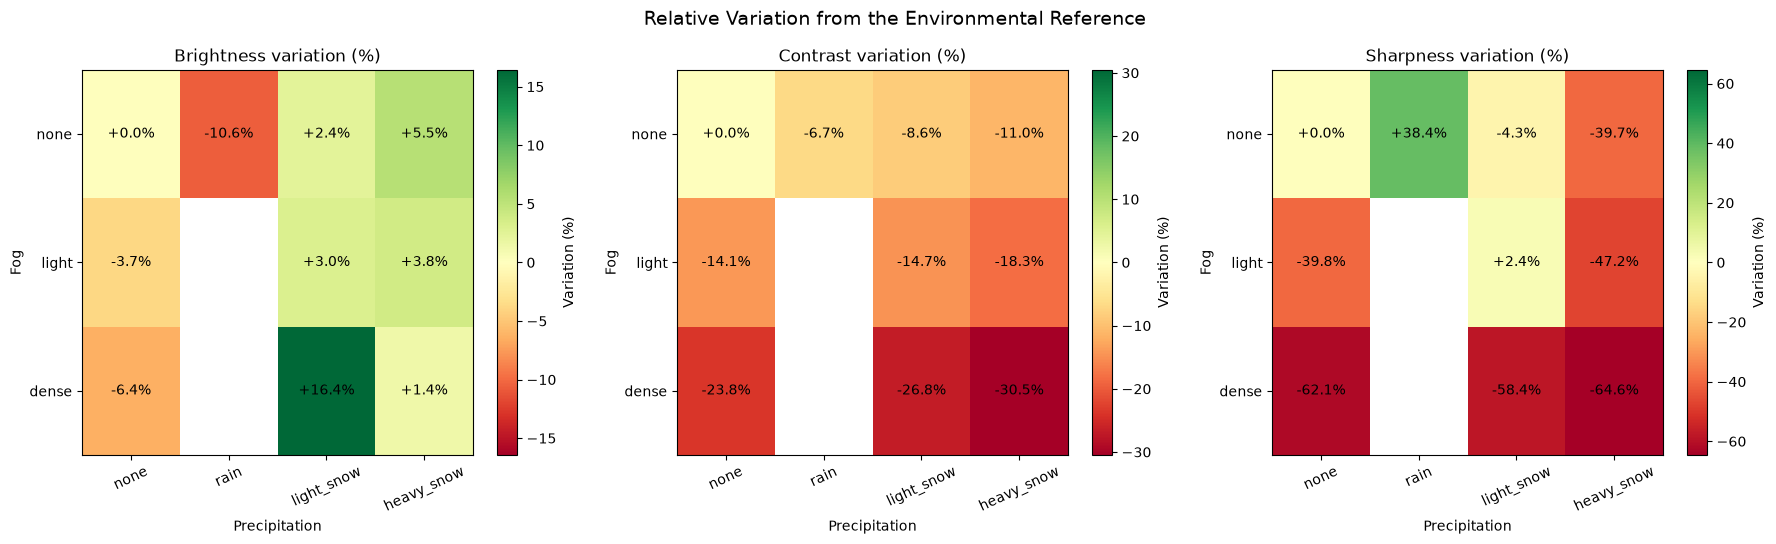

In [19]:
from matplotlib.colors import TwoSlopeNorm

variation_titles = {
    "brightness_variation_pct": "Brightness variation (%)",
    "contrast_variation_pct": "Contrast variation (%)",
    "sharpness_variation_pct": "Sharpness variation (%)"
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

for ax, (metric, title) in zip(axes, variation_titles.items()):
    matrix = relative_quality.pivot(
        index="fog_condition",
        columns="precipitation_condition",
        values=metric
    ).reindex(index=fog_order, columns=precip_order)

    values = matrix.to_numpy(dtype=float)
    finite = values[np.isfinite(values)]
    limit = max(abs(finite.min()), abs(finite.max()))

    im = ax.imshow(
        values,
        cmap="RdYlGn",
        norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
        aspect="auto"
    )

    ax.set_xticks(range(len(precip_order)))
    ax.set_xticklabels(precip_order, rotation=25)
    ax.set_yticks(range(len(fog_order)))
    ax.set_yticklabels(fog_order)
    ax.set_title(title)
    ax.set_xlabel("Precipitation")
    ax.set_ylabel("Fog")

    for i in range(len(fog_order)):
        for j in range(len(precip_order)):
            value = values[i, j]
            if np.isfinite(value):
                ax.text(j, i, f"{value:+.1f}%", ha="center", va="center")

    fig.colorbar(im, ax=ax, label="Variation (%)")

plt.suptitle("Relative Variation from the Environmental Reference", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_relative_quality_heatmaps.png", dpi=180)
plt.show()

### 13.1 Interpretation of Relative Variation

The reference condition is `no fog + no precipitation`, with median brightness 93.61, contrast 41.79, and sharpness 143.69.

For `dense fog + heavy snow`, the relative variations are:

- **Brightness:** +1.40%.
- **Contrast:** −30.49%.
- **Sharpness:** −64.62%.

Brightness remains close to the reference value, while contrast and sharpness are substantially lower. This reinforces that brightness alone is not a sufficient indicator of visual quality.

These variations compare medians descriptively. They do not represent causal effects or confidence intervals. Cells with small sample sizes require particular caution.

## 14. General Discussion

The results show that RGB image metrics respond differently to environmental conditions:

- **Brightness** varies with illumination and scene composition, but does not show a uniform degradation trend under fog and precipitation.
- **Global contrast** has progressively lower medians in the more severe precipitation categories and in combinations involving fog.
- **Laplacian-based sharpness** decreases markedly with fog severity and reaches particularly low values in the dense-fog/heavy-snow combination.

The absence of rain-and-fog combinations in the contingency table is a coverage limitation of the analysed annotations. It should not be extrapolated into a physical impossibility or used to conclude how a system would behave under simultaneous rain and fog.

Overall, the results motivate investigating perception strategies that account for camera reliability rather than relying on a single image-quality indicator. This motivation must still be tested against actual detection performance.

## 15. Limitations

1. **Global indicators:** brightness, contrast, and Laplacian variance are computed over the entire image; they do not directly measure the visibility of each object.
2. **Confounding variables:** illumination, scene type, road condition, exposure, motion, and visual content may affect the metrics.
3. **Class imbalance:** the rain category contains 282 images, and dense fog/light snow contains only 45.
4. **Combination coverage:** no images in the analysed annotations are labelled with simultaneous rain and fog.
5. **Temporal dependence:** images from the same sequence or drive may be correlated. The statistical tests do not explicitly model this dependence.
6. **Statistical significance:** a small p-value does not quantify practical magnitude or establish causality.
7. **No detector evaluation:** detection metrics have not yet been calculated, and the impact of these conditions on YOLO has not yet been tested.

## 16. Conclusions

1. RGB image metrics and environmental labels were successfully integrated for **12,997 images**, with a one-to-one correspondence in the master CSV.
2. Images labelled as night have lower mean brightness than images labelled as day. The twilight label overlaps with both day and night and must be analysed as an independent dimension.
3. Median sharpness decreases from 141.37 with no fog to 94.76 with light fog and 54.13 with dense fog. The non-parametric tests identified differences between the groups.
4. Median contrast decreases from 40.53 with no precipitation to 34.14 with heavy snow. The statistical comparisons identified differences between the observed precipitation categories.
5. Among the available environmental combinations, dense fog + heavy snow has the lowest median contrast (29.05) and sharpness (50.84).
6. Brightness alone does not reflect visual degradation: in dense fog + heavy snow it remains close to the reference (+1.40%), while contrast and sharpness decrease by 30.49% and 64.62%, respectively.
7. Rain does not appear in combination with fog in the analysed annotations. This limits the study of rain + fog but does not imply that the two conditions cannot coexist in real scenarios.

### Overall Conclusion

The exploratory analysis identifies a consistent association between more severe fog conditions and lower sharpness, as well as between more severe precipitation and lower contrast. These findings provide an initial characterization of RGB visual degradation in *Seeing Through Fog* and motivate further evaluation of perception robustness under adverse conditions.

However, image quality is not equivalent to perception performance. The next stage must verify the 2D object annotations and evaluate a baseline detector against correctly associated ground truth.